# Data Visualization of taxi data

## 1) Loading the Taxis Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=sns.load_dataset("taxis")

In [3]:
df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [4]:
df.shape

(6433, 14)

In [5]:
df.duplicated().sum()

np.int64(0)

## 2) Handling Missing Values

In [6]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,44


In [7]:
df["payment"].fillna(df["payment"].mode()[0],inplace=True)

#filled the mode value on payment column

/tmp/ipykernel_45877/2201725794.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["payment"].fillna(df["payment"].mode()[0],inplace=True)


In [8]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


In [9]:
df[df["pickup_zone"].isnull() & df["dropoff_zone"].isnull()]

#found all the null values in both drop and pick zones

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
42,2019-03-30 23:59:14,2019-03-30 23:59:17,1,0.00,80.0,20.08,0.00,100.38,yellow,credit card,NaN,NaN,NaN,NaN
622,2019-03-12 19:52:36,2019-03-12 19:52:55,3,0.00,120.0,33.20,12.50,166.00,yellow,credit card,NaN,NaN,NaN,NaN
970,2019-03-29 00:02:00,2019-03-29 00:02:05,2,0.00,45.0,5.00,0.00,50.30,yellow,credit card,NaN,NaN,NaN,NaN
1108,2019-03-10 09:33:13,2019-03-10 09:52:04,1,13.40,52.0,11.70,5.76,70.26,yellow,credit card,NaN,NaN,NaN,NaN
2137,2019-03-08 13:27:32,2019-03-08 13:46:23,1,1.40,12.0,3.05,0.00,18.35,yellow,credit card,NaN,NaN,NaN,NaN
2742,2019-03-23 06:20:27,2019-03-23 06:20:59,1,0.00,55.0,0.00,0.00,55.80,yellow,credit card,NaN,NaN,NaN,NaN
3085,2019-03-24 15:43:02,2019-03-24 16:02:57,1,3.20,14.5,0.00,0.00,15.30,yellow,cash,NaN,NaN,NaN,NaN
3259,2019-03-30 00:39:09,2019-03-30 00:43:34,1,0.84,5.0,1.70,0.00,10.50,yellow,credit card,NaN,NaN,NaN,NaN
3644,2019-03-19 23:30:50,2019-03-19 23:32:33,2,0.00,103.0,20.65,0.00,123.95,yellow,credit card,NaN,NaN,NaN,NaN
3889,2019-03-30 06:42:55,2019-03-30 06:43:00,1,0.00,2.5,0.00,0.00,3.30,yellow,cash,NaN,NaN,NaN,NaN


In [10]:
df.dropna(
    subset=["pickup_zone","dropoff_zone"],how="all",
    inplace=True
)

#dropped the pickup and dropoff zone null values where both columns are null

In [11]:
df.isnull().sum()

,0
pickup,0
dropoff,0
passengers,0
distance,0
fare,0
tip,0
tolls,0
total,0
color,0
payment,0


In [12]:
df[df["pickup_zone"].isnull() & df["pickup_borough"].isnull()]

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
606,2019-03-19 15:04:40,2019-03-19 15:06:15,1,0.40,3.5,1.35,0.00,8.15,yellow,credit card,NaN,Upper East Side South,NaN,Manhattan
671,2019-03-09 22:45:46,2019-03-09 22:46:50,1,0.40,3.5,0.00,0.00,7.30,yellow,cash,NaN,Lincoln Square East,NaN,Manhattan
712,2019-03-03 01:24:45,2019-03-03 01:29:32,1,0.80,5.0,1.75,0.00,10.55,yellow,credit card,NaN,West Chelsea/Hudson Yards,NaN,Manhattan
1961,2019-03-19 16:43:59,2019-03-19 17:37:22,1,17.82,52.0,13.11,5.76,78.67,yellow,credit card,NaN,Garment District,NaN,Manhattan
3793,2019-03-24 06:07:30,2019-03-24 06:12:22,1,1.50,6.5,0.00,0.00,9.80,yellow,credit card,NaN,Midtown East,NaN,Manhattan


In [13]:
df["pickup_zone"].fillna(df["pickup_zone"].mode()[0],inplace=True)
df["pickup_borough"].fillna(df["pickup_borough"].mode()[0],inplace=True)

#filled the null value with mode value for both pickup_borough & pickup_zone

/tmp/ipykernel_45877/3759409045.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["pickup_zone"].fillna(df["pickup_zone"].mode()[0],inplace=True)
/tmp/ipykernel_45877/3759409045.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, 

In [14]:
df[df["dropoff_zone"].isnull() & df["dropoff_borough"].isnull()]

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
711,2019-03-21 17:39:50,2019-03-21 18:12:54,2,1.74,17.0,4.26,0.00,25.56,yellow,credit card,Midtown East,NaN,Manhattan,NaN
739,2019-03-14 00:09:17,2019-03-14 00:09:21,1,0.03,2.5,0.00,0.00,3.80,yellow,cash,Upper East Side South,NaN,Manhattan,NaN
1112,2019-03-12 19:09:23,2019-03-12 19:20:46,1,0.90,8.5,1.92,0.00,14.72,yellow,credit card,Times Sq/Theatre District,NaN,Manhattan,NaN
1230,2019-03-29 07:52:46,2019-03-29 08:02:40,1,0.90,5.5,1.76,0.00,10.56,yellow,credit card,Yorkville East,NaN,Manhattan,NaN
1690,2019-03-22 06:24:14,2019-03-22 06:24:14,1,0.00,72.0,0.00,0.00,72.00,yellow,credit card,East New York,NaN,Brooklyn,NaN
1787,2019-03-28 06:58:57,2019-03-28 07:18:10,1,6.32,20.5,4.26,0.00,25.56,yellow,credit card,Manhattan Valley,NaN,Manhattan,NaN
2089,2019-03-12 16:21:28,2019-03-12 16:43:40,1,5.69,21.0,0.00,0.00,22.80,yellow,cash,JFK Airport,NaN,Queens,NaN
2180,2019-03-09 15:00:06,2019-03-09 15:50:29,2,14.82,50.5,0.00,2.64,53.94,yellow,credit card,Flatiron,NaN,Manhattan,NaN
2231,2019-03-11 10:17:31,2019-03-11 11:03:55,1,26.35,130.0,0.00,5.76,136.56,yellow,cash,East Harlem North,NaN,Manhattan,NaN
2402,2019-03-29 22:29:40,2019-03-29 22:54:28,3,19.20,84.0,0.00,0.00,85.30,yellow,cash,JFK Airport,NaN,Queens,NaN


In [15]:
df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0],inplace=True)
df["dropoff_borough"].fillna(df["dropoff_borough"].mode()[0],inplace=True)

#filled the null value with mode value for both dropoff_borough & dropoff_zone

/tmp/ipykernel_45877/982650209.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["dropoff_zone"].fillna(df["dropoff_zone"].mode()[0],inplace=True)
/tmp/ipykernel_45877/982650209.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, 

In [29]:
df.describe()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total
count,6412,6412,6412.000000,6412.000000,6412.000000,6412.000000,6412.000000,6412.000000
mean,2019-03-16 08:25:31.815190272,2019-03-16 08:39:54.354179328,1.540237,3.029576,13.039983,1.967545,0.322592,18.458614
min,2019-02-28 23:29:03,2019-02-28 23:32:35,0.000000,0.000000,1.000000,0.000000,0.000000,1.300000
25%,2019-03-08 15:47:46,2019-03-08 16:08:02,1.000000,0.990000,6.500000,0.000000,0.000000,10.800000
50%,2019-03-15 21:43:15.500000,2019-03-15 22:02:12.500000,1.000000,1.650000,9.500000,1.700000,0.000000,14.160000
75%,2019-03-23 17:37:37.249999872,2019-03-23 17:49:59.750000128,2.000000,3.212500,15.000000,2.790000,0.000000,20.300000
max,2019-03-31 23:43:45,2019-04-01 00:13:58,6.000000,36.700000,150.000000,23.190000,24.020000,174.820000
std,NaN,NaN,1.205239,3.829226,11.372453,2.394117,1.406024,13.574468


### here we know that the average fare rate is 13 per trip
### and average tip value was 1.96

# 3) Visualizations using Matplotlib/Pandas Plot:

### Line Chart



In [17]:
df["pickup"]=pd.to_datetime(df["pickup"])

df=df.sort_values(by="pickup")

plt.figure(figsize=(200,17))
plt.plot(df["pickup"],df["fare"])
plt.title("Fare rate over time")
plt.show()

### Bar chart


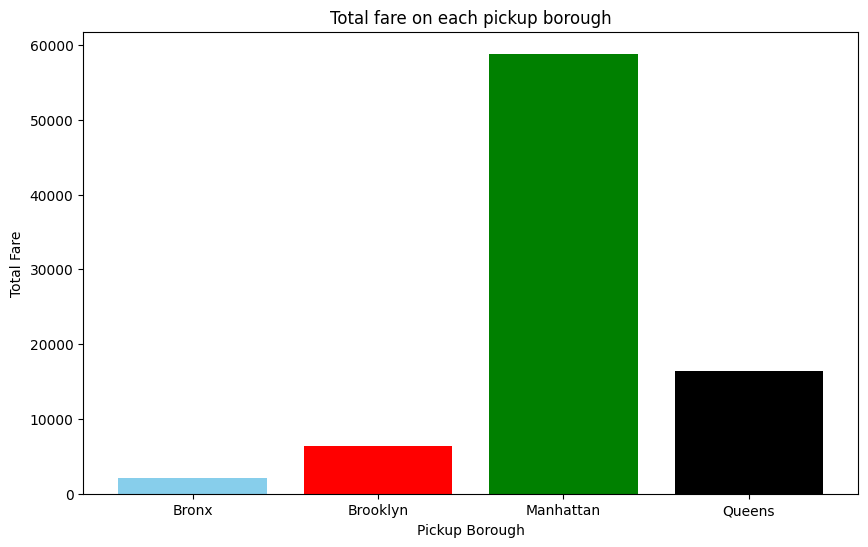

In [18]:
borough_group=df.groupby("pickup_borough")
borough_fare = borough_group["fare"].sum()

plt.figure(figsize=(10, 6))
plt.bar(borough_fare.index,borough_fare.values, color=["skyblue","red","green","black"])
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.title("Total fare on each pickup borough")
plt.show()

### Pie chart

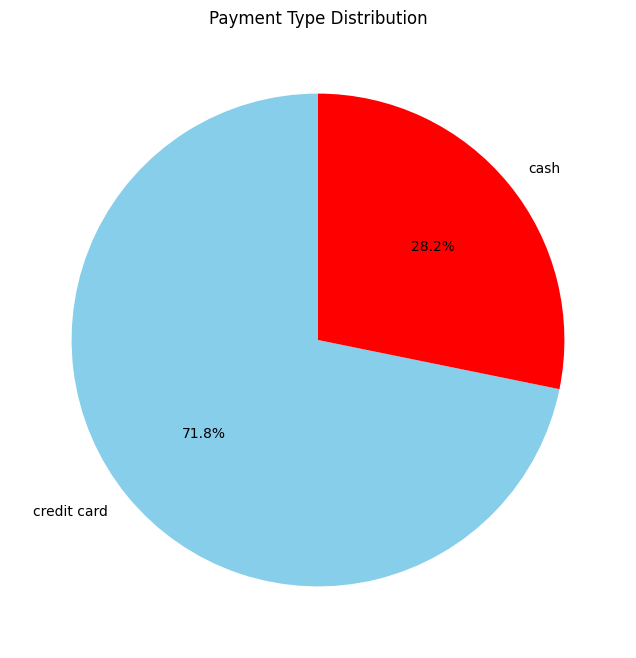

In [35]:
payment_counts = df["payment"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%.1f%%',
    startangle=90,
    colors=["skyBlue","red"]

)
plt.title("Payment Type Distribution")
plt.show()

### Histogram

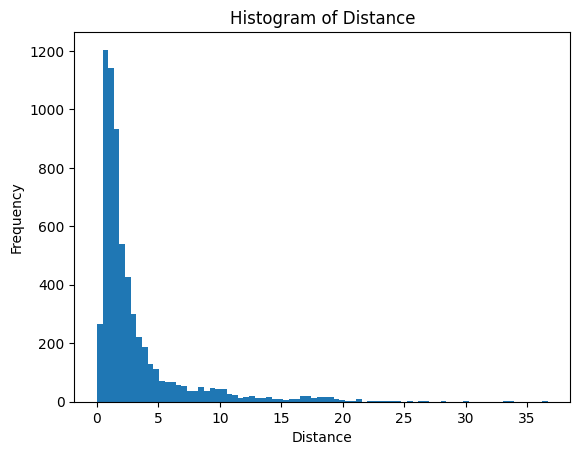

In [20]:
plt.hist(df["distance"], bins=80)
plt.title("Histogram of Distance")
plt.xlabel("Distance")
plt.ylabel("Frequency")
plt.show()

### Box Plot

<Figure size 1200x800 with 0 Axes>

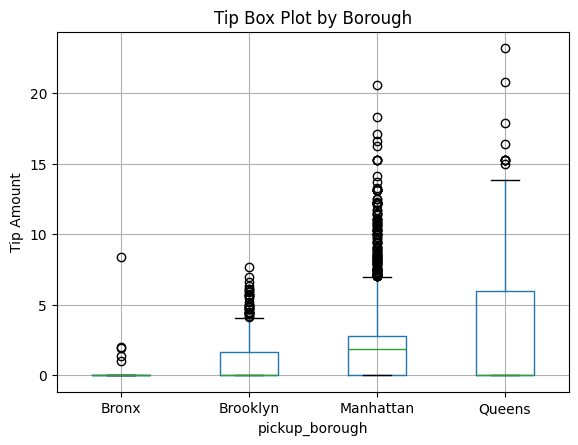

In [21]:
plt.figure(figsize=(12, 8))
df.boxplot(column="tip", by="pickup_borough")
plt.title("Tip Box Plot by Borough")
plt.ylabel("Tip Amount")
plt.suptitle("")
plt.show()

# Visualizations using Seaborn:

### Count Plot

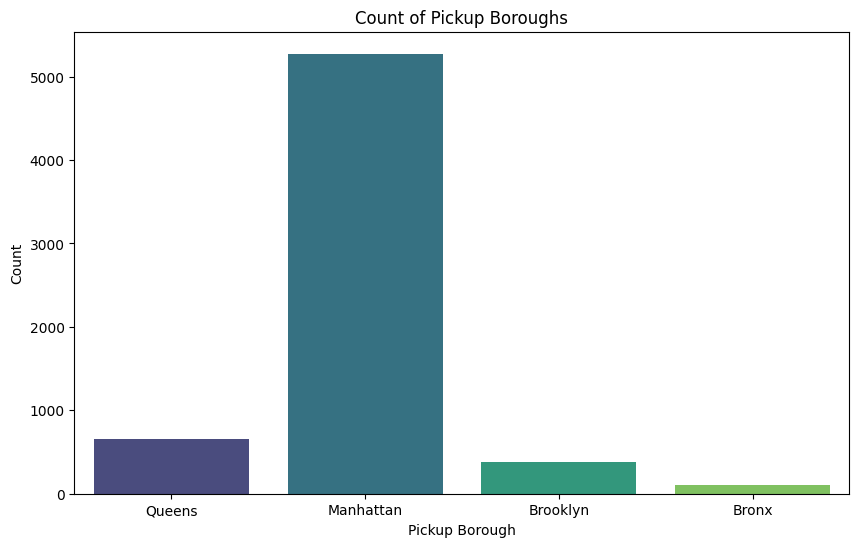

In [22]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x="pickup_borough",hue= "pickup_borough", palette="viridis")
plt.xlabel("Pickup Borough")
plt.ylabel("Count")
plt.title("Count of Pickup Boroughs")
plt.show()


### Scatter Plot

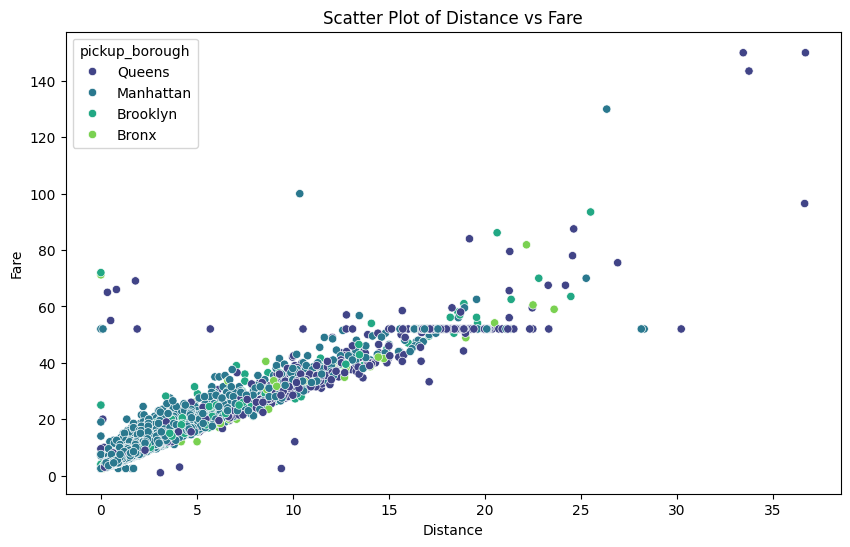

In [23]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="distance",y="fare",hue ="pickup_borough", palette="viridis")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.title("Scatter Plot of Distance vs Fare")
plt.show()


In [24]:
df_corr=df.corr(numeric_only=True)

### Heatmap

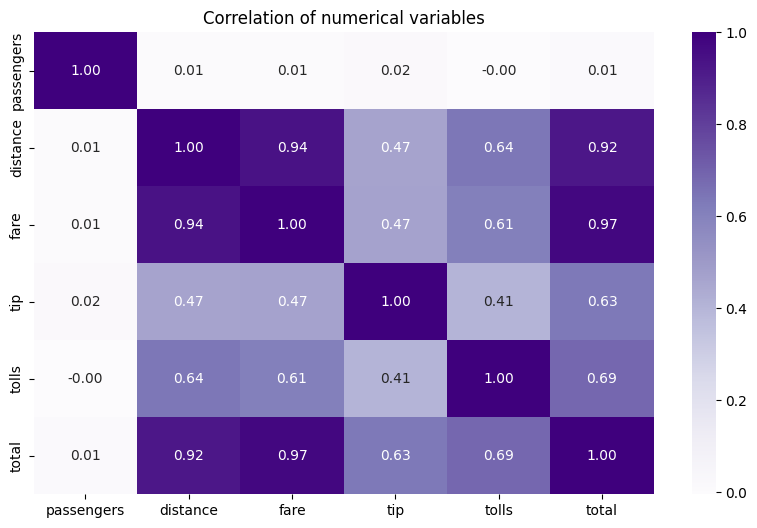

In [25]:

plt.figure(figsize=(10, 6))
plt.title("Correlation of numerical variables")
sns.heatmap(df_corr,cmap="Purples" ,annot=True,fmt=".2f")
plt.show()

### Pair Plot

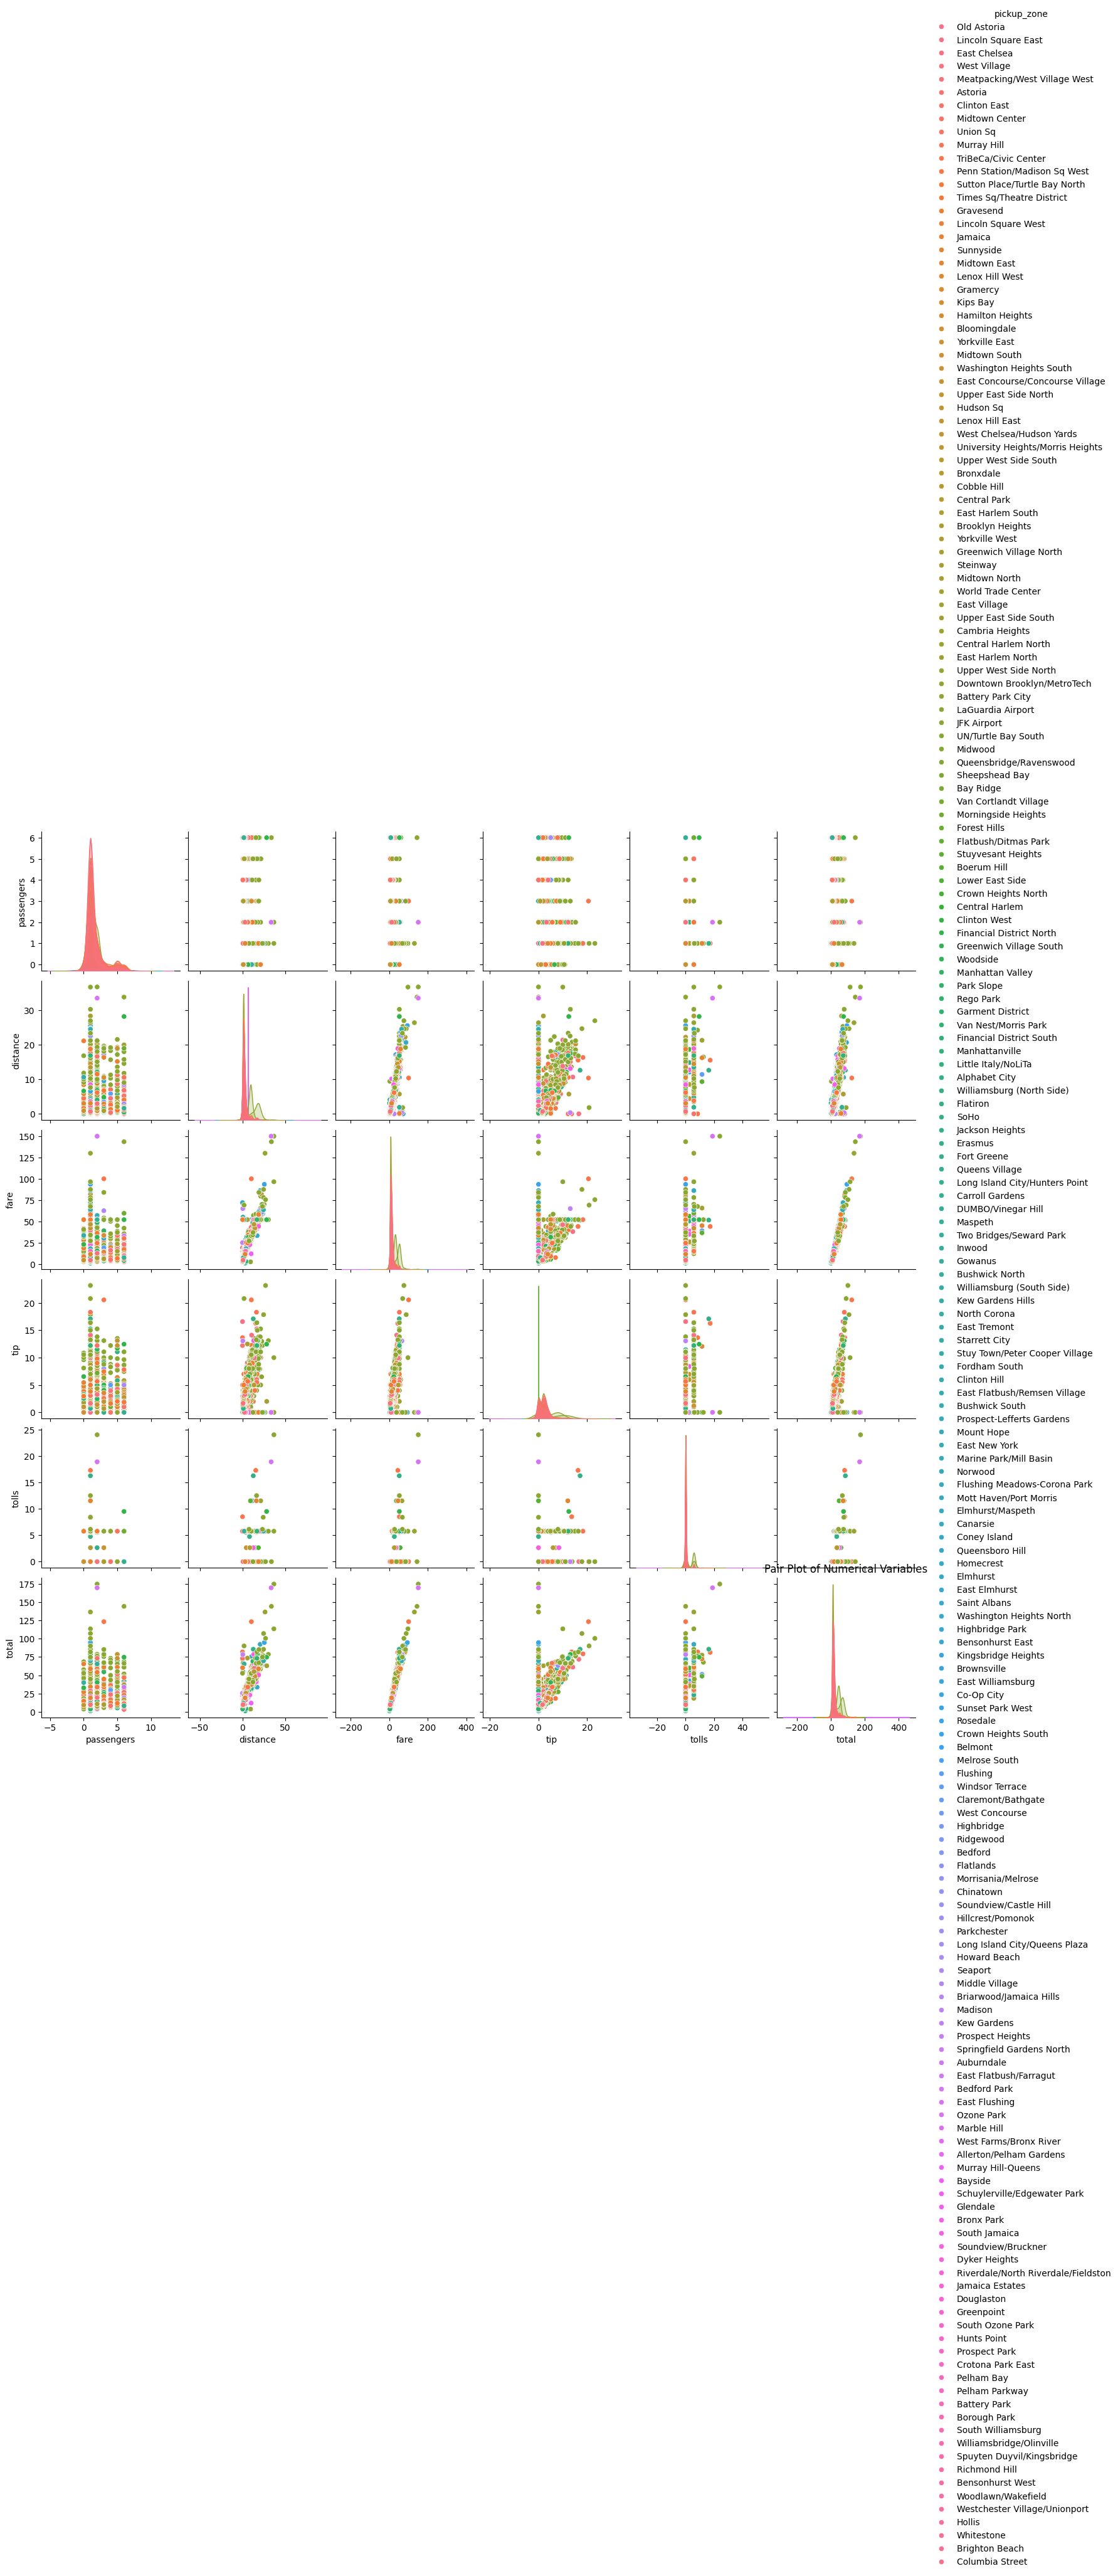

In [30]:
sns.pairplot(data=df,hue="pickup_zone")
plt.title("Pair Plot of Numerical Variables")
plt.show()

### Violin plot

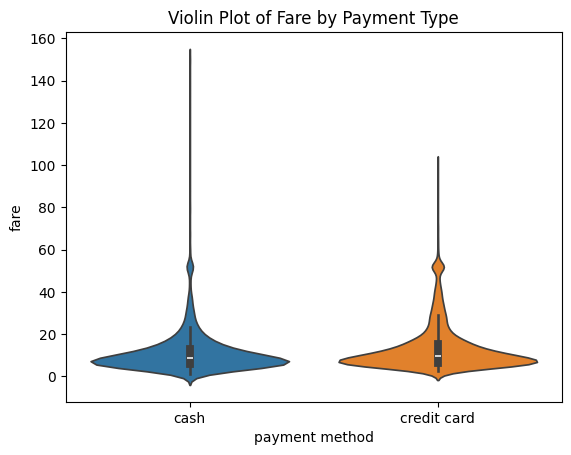

In [27]:
sns.violinplot(
    data=df,x="payment",y="fare",hue="payment"
    )
plt.title("Violin Plot of Fare by Payment Type")
plt.xlabel("payment method")
plt.ylabel("fare")
plt.show()